In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RESULTS_FOLDER = Path("../../results/LR_uci_results")
RESULTS_FOLDER.mkdir(parents=True, exist_ok=True)

# Load the features made by build_features.py
data = pd.read_csv("../../data/processed/uci/uci_features.csv")
LABEL_COLUMNS = ["split", "activity", "participant", "position", "platform", "recording_id"]

train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

X_train, y_train = train.drop(columns=LABEL_COLUMNS), train["activity"]
X_test, y_test = test.drop(columns=LABEL_COLUMNS), test["activity"]

print(f"Train: {X_train.shape}   Test: {X_test.shape}")

Train: (3285, 84)   Test: (1387, 84)


In [3]:
# Learn the scaling from the training data only, and scale it
scaler = MinMaxScaler(feature_range=(-1, 1))
X_train_scaled = scaler.fit_transform(X_train)

# Scale the test data using the training data's min and max
X_test_scaled = scaler.transform(X_test)

# Train and predict on the scaled data
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)
predictions = lr.predict(X_test_scaled)

print("Model: Logistic Regression")
print("Dataset: UCI")
print(f"Accuracy: {accuracy_score(y_test, predictions):.3f}")
print(f"Macro F1: {f1_score(y_test, predictions, average='macro'):.3f}\n")
print(classification_report(y_test, predictions, digits=3))

Model: Logistic Regression
Dataset: UCI
Accuracy: 0.872
Macro F1: 0.871

                    precision    recall  f1-score   support

           walking      0.831     0.944     0.884       496
walking_downstairs      0.869     0.881     0.875       420
  walking_upstairs      0.932     0.788     0.854       471

          accuracy                          0.872      1387
         macro avg      0.877     0.871     0.871      1387
      weighted avg      0.877     0.872     0.871      1387



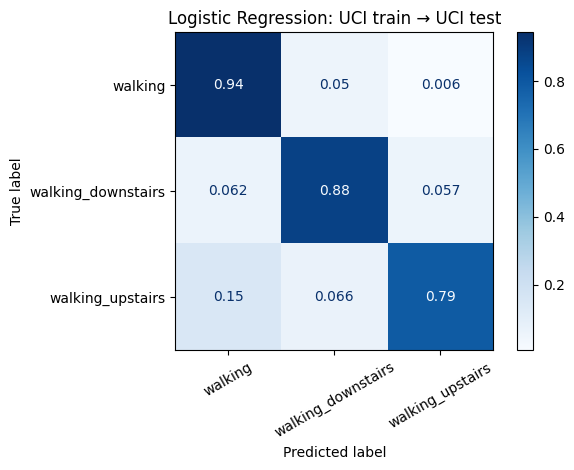

In [4]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions, normalize="true",
                                        cmap="Blues", xticks_rotation=30)
plt.title("Logistic Regression: UCI train → UCI test")
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "LR_uci_confusion_matrix.png", dpi=150)
plt.show()

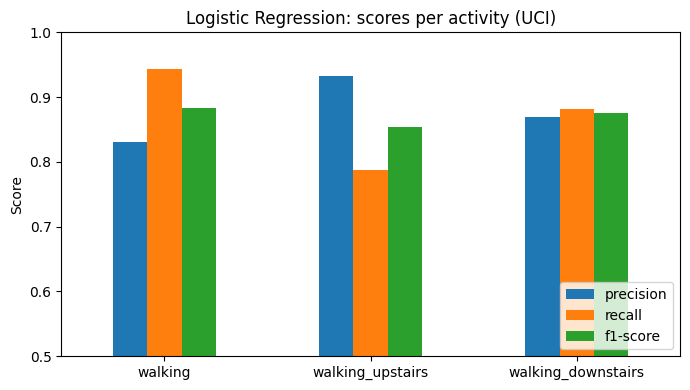

In [5]:
report = pd.DataFrame(classification_report(y_test, predictions, output_dict=True)).T
per_activity = report.loc[["walking", "walking_upstairs", "walking_downstairs"], ["precision", "recall", "f1-score"]]

per_activity.plot(kind="bar", figsize=(7, 4), ylim=(0.5, 1), rot=0)
plt.title("Logistic Regression: scores per activity (UCI)")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "LR_uci_per_activity.png", dpi=150)
plt.show()